# 2. Customer segmentation

Who are the customers, which ones matter most, and which ones are slipping away?

Each customer is described by three things: days since their last order, how many orders they have placed, and how much they have spent. This is the standard recency, frequency and spend approach. Customers are scored 1 to 5 on recency and on frequency, and the two scores place them in one of seven named segments. The seventh, Big spenders, also looks at spend. The end of this notebook shows why it was added.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
from retail_analysis.clean import SHOPS, load, clean, open_shop
from retail_analysis.segmentation import GROUPS

plt.style.use("dark_background")
plt.rcParams.update({"figure.facecolor": "black", "axes.facecolor": "black", "axes.edgecolor": "#3a3b3e", "axes.grid": True,
                     "grid.color": "#1c1c1e", "figure.figsize": (11, 4.5), "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
WHITE, SILVER, GREY, JADE, RED = "#f2f2f0", "#d4d6da", "#8d8d90", "#5fd0a0", "#e0787a"
COLORS = dict(zip(GROUPS, ["#7fb4d8", JADE, "#9fd9bd", WHITE, SILVER, "#c9a25a", GREY]))
money = lambda v, _=None: f"£{v:,.0f}"
UK, AMAZON, GROCERY = SHOPS

sales, removed = open_shop(UK)
from retail_analysis.segmentation import summarize, scores, group, by_group, profile, repeat_buying

customers = summarize(sales)
customers["group"] = group(customers)

## The seven segments

In [2]:
table = by_group(customers)
table.style.format({"customers": "{:,.0f}", "spend": "£{:,.0f}", "typical_orders": "{:.0f}", "typical_days_since": "{:.0f}", "share_of_customers": "{:.0%}", "share_of_spend": "{:.0%}"})

,customers,spend,typical_orders,typical_days_since,share_of_customers,share_of_spend
group,,,,,,
Big spenders,182,"£3,667,774",18,6,4%,44%
Best customers,933,"£1,994,315",6,11,22%,24%
Regulars,825,"£1,148,602",3,37,19%,14%
New,234,"£80,716",1,18,5%,1%
Occasional,420,"£206,768",1,49,10%,2%
Going quiet,654,"£732,613",3,132,15%,9%
Lost,"1,076","£442,066",1,218,25%,5%


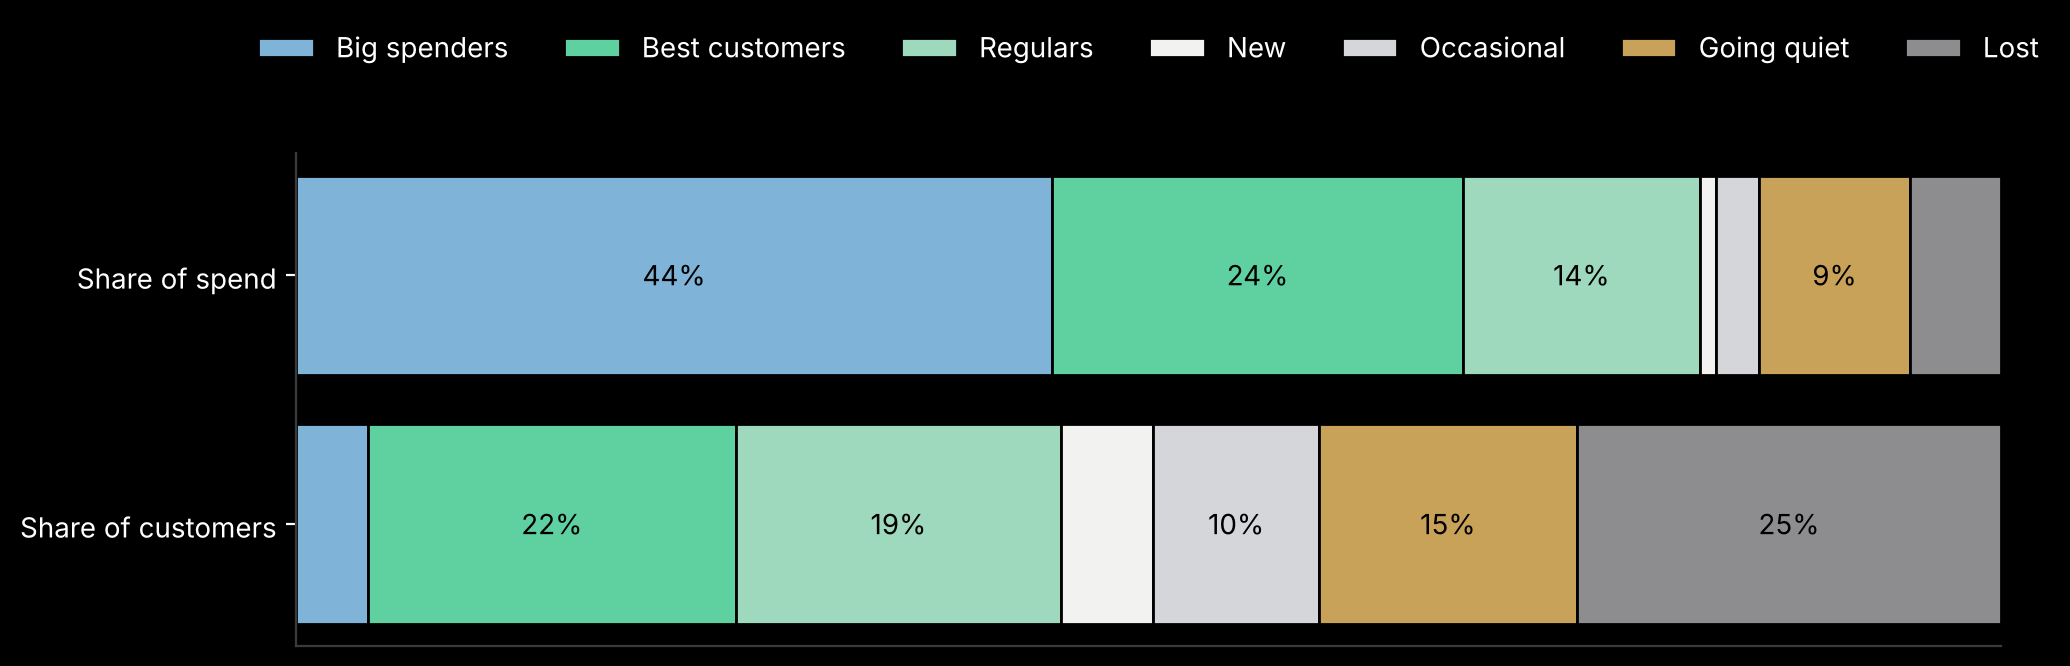

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for row, column in enumerate(["share_of_customers", "share_of_spend"]):
    left = 0
    for name in table.index:
        ax.barh(row, table.loc[name, column], left=left, color=COLORS[name], edgecolor="black", label=name if row == 0 else None)
        if table.loc[name, column] > 0.06:
            ax.text(left + table.loc[name, column] / 2, row, f"{table.loc[name, column]:.0%}", ha="center", va="center", color="black", fontsize=10)
        left += table.loc[name, column]
ax.set_yticks([0, 1], ["Share of customers", "Share of spend"]); ax.set_xlim(0, 1); ax.xaxis.set_visible(False); ax.grid(False)
ax.legend(frameon=False, ncol=7, loc="upper center", bbox_to_anchor=(0.5, 1.3))
plt.show()

Big spenders are 4 percent of customers and 44 percent of the money. With Best customers, a quarter of the list brings in more than two thirds of it.

## How the segments are drawn

Every customer sits in one square of this grid. The number is how many customers are in the square and the color is the segment it belongs to. Two segments sit on top of the grid. New is a single order, placed recently. Big spenders are the Best customers who are also in the top twentieth of all customers by spend.

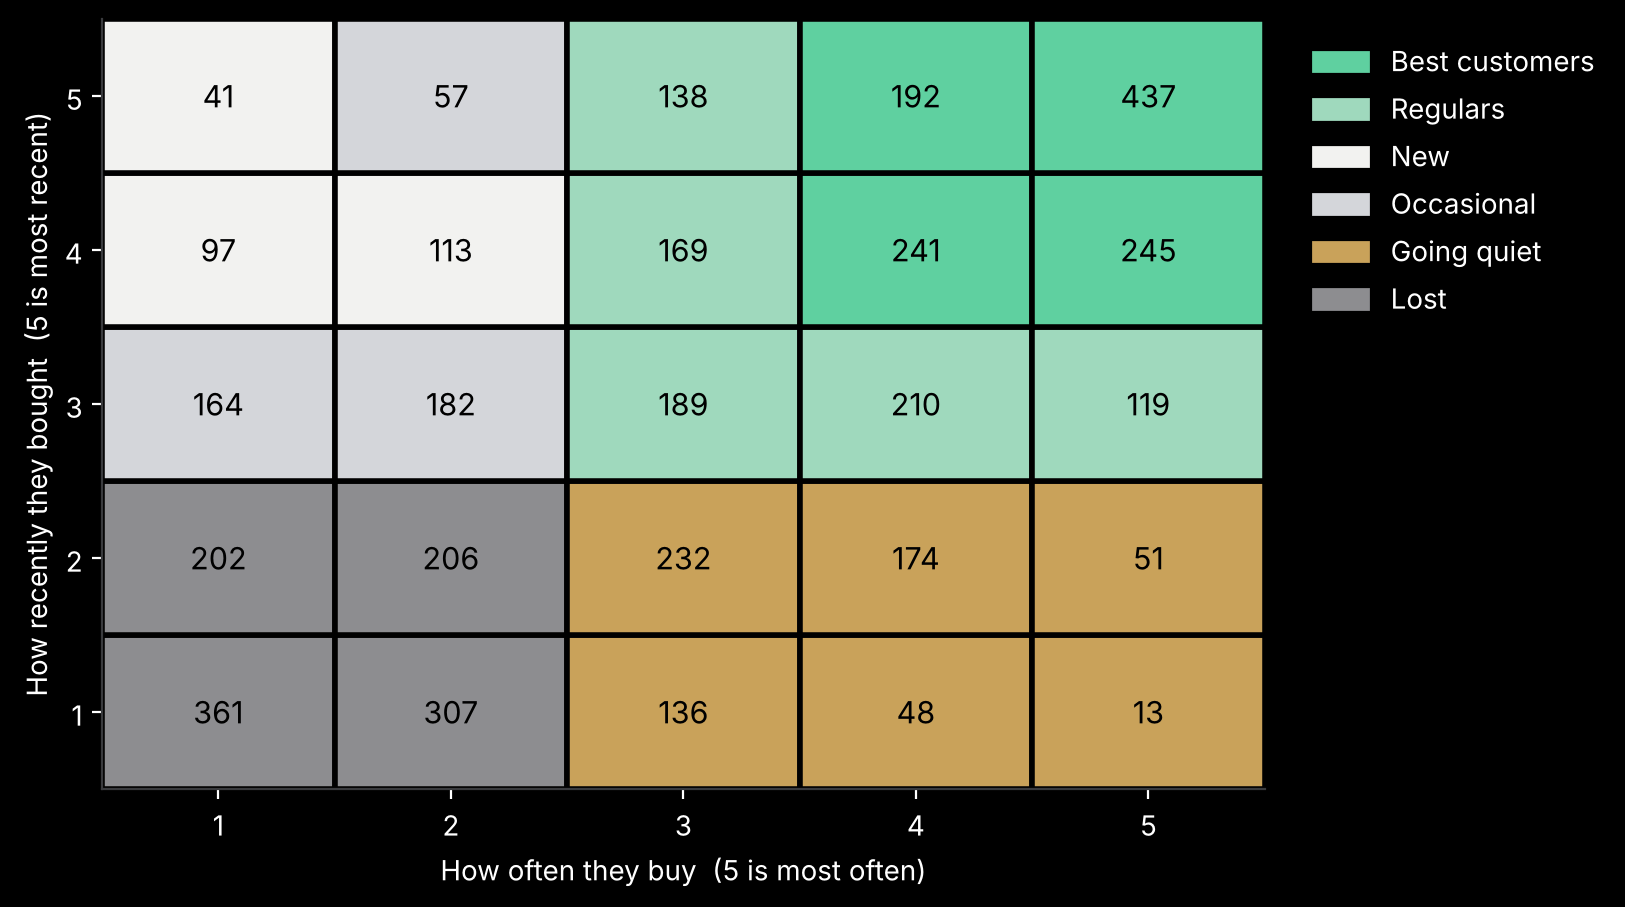

In [4]:
recent, often = scores(customers)
grid = pd.crosstab(recent, often)
owner = customers["group"].replace("Big spenders", "Best customers").groupby([recent, often]).agg(lambda g: g.mode()[0]).unstack()
fig, ax = plt.subplots(figsize=(7.5, 5))
for r in grid.index:
    for f in grid.columns:
        ax.add_patch(plt.Rectangle((f - 0.5, r - 0.5), 1, 1, color=COLORS[owner.loc[r, f]], ec="black", lw=2))
        ax.text(f, r, f"{grid.loc[r, f]:,}", ha="center", va="center", color="black", fontsize=11)
ax.set_xlim(0.5, 5.5); ax.set_ylim(0.5, 5.5); ax.grid(False)
ax.set_xlabel("How often they buy  (5 is most often)"); ax.set_ylabel("How recently they bought  (5 is most recent)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORS[g]) for g in GROUPS[1:]], labels=GROUPS[1:], frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## Every customer

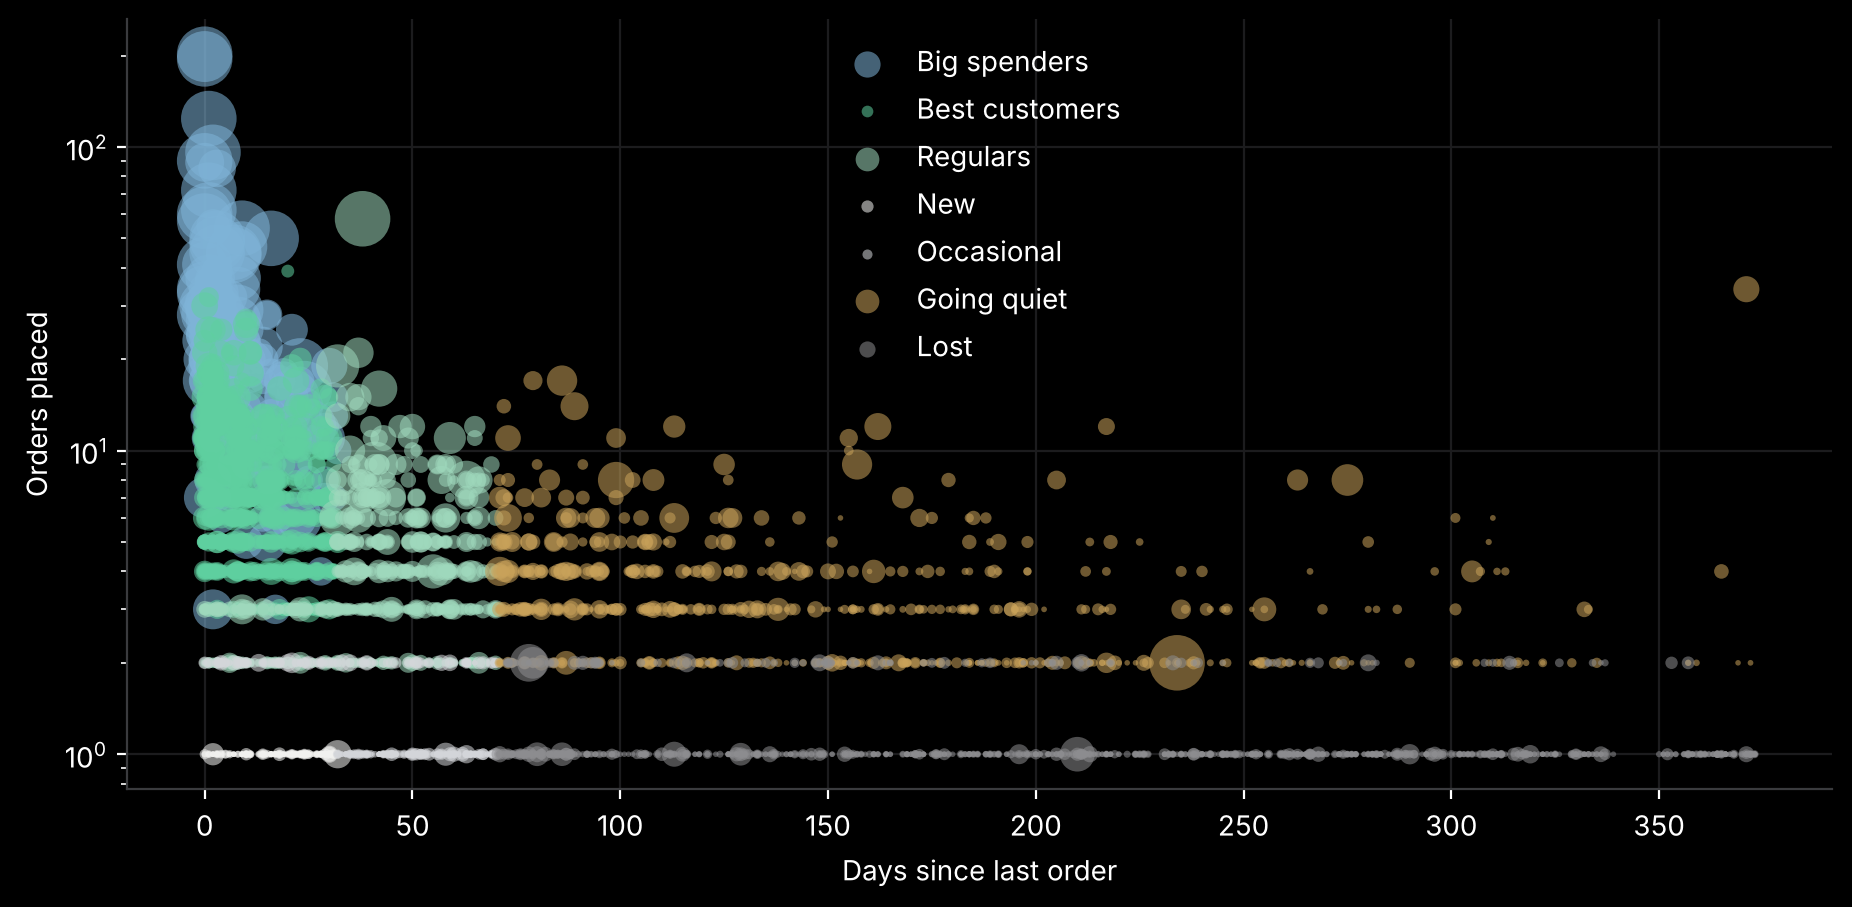

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
for name in GROUPS:
    part = customers[customers.group == name]
    ax.scatter(part.days_since, part.orders, s=np.clip(part.spend / 60, 4, 400), color=COLORS[name], alpha=0.55, linewidths=0, label=name)
ax.set_yscale("log"); ax.set_xlabel("Days since last order"); ax.set_ylabel("Orders placed"); ax.legend(frameon=False, markerscale=0.6)
plt.show()

Each dot is a customer and its size is their spend.

## How each segment shops, and what to do about it

**Leans toward** lists the products a segment spends a bigger share on than customers as a whole.

In [6]:
profile(sales, customers).style.format({"average_order": "£{:,.0f}", "products_per_order": "{:.0f}", "orders_per_customer": "{:.1f}"})

,average_order,products_per_order,orders_per_customer,leans_toward,what_to_do
group,,,,,
Big spenders,£812,21,24.8,"Vintage Union Jack Memoboard, Black Heart Card Holder, Doormat Black Flock","Know them by name. A direct contact, and a call if they go quiet."
Best customers,£303,21,7.1,"Gardeners Kneeling Pad Cup Of Tea, Hot Water Bottle I Am So Poorly, Hot Water Bottle Keep Calm","Keep them. Early access, a thank you, no discounts they do not need."
Regulars,£383,22,3.6,"Feltcraft Cushion Rabbit, Grow A Flytrap Or Sunflower In Tin, Feltcraft Cushion Owl",Grow them. Suggest the products their group buys together.
New,£345,26,1.0,"Metal Sign Take It Or Leave It, Baking Set Spaceboy Design, White Skull Hot Water Bottle",Win the second order. A follow up within a few weeks of the first.
Occasional,£380,25,1.3,"Hand Warmer Union Jack, Christmas Lights 10 Reindeer, Love Hot Water Bottle",Low effort. Include in seasonal mailings.
Going quiet,£331,17,3.4,"Fairy Cake Flannel Assorted Colour, Set/4 White Retro Storage Cubes, Doormat Fairy Cake",Contact now. They were good customers and half can still be won back.
Lost,£375,19,1.1,"Small Popcorn Holder, Round Snack Boxes Set Of 4 Fruits, Assorted Colours Silk Fan","Do not spend much. One last offer, then stop."


## Going quiet: the list to act on

People who ordered several times and have not been back in months.

In [7]:
quiet = customers[customers.group == "Going quiet"].nlargest(10, "spend")[["orders", "spend", "days_since"]]
quiet.style.format({"spend": "£{:,.0f}", "orders": "{:.0f}", "days_since": "{:.0f}"})

,orders,spend,days_since
customer,,,
15749,2,"£24,851",234
16180,8,"£10,227",99
13093,8,"£7,798",275
16745,17,"£7,171",86
12980,9,"£7,092",157
13027,6,"£6,912",113
16182,4,"£6,618",71
15939,14,"£6,087",89
14101,6,"£5,977",73


## Do customers come back?

Each row is the set of customers who placed their first order in that month. Each column is a later month. The number is the share of them who ordered again.

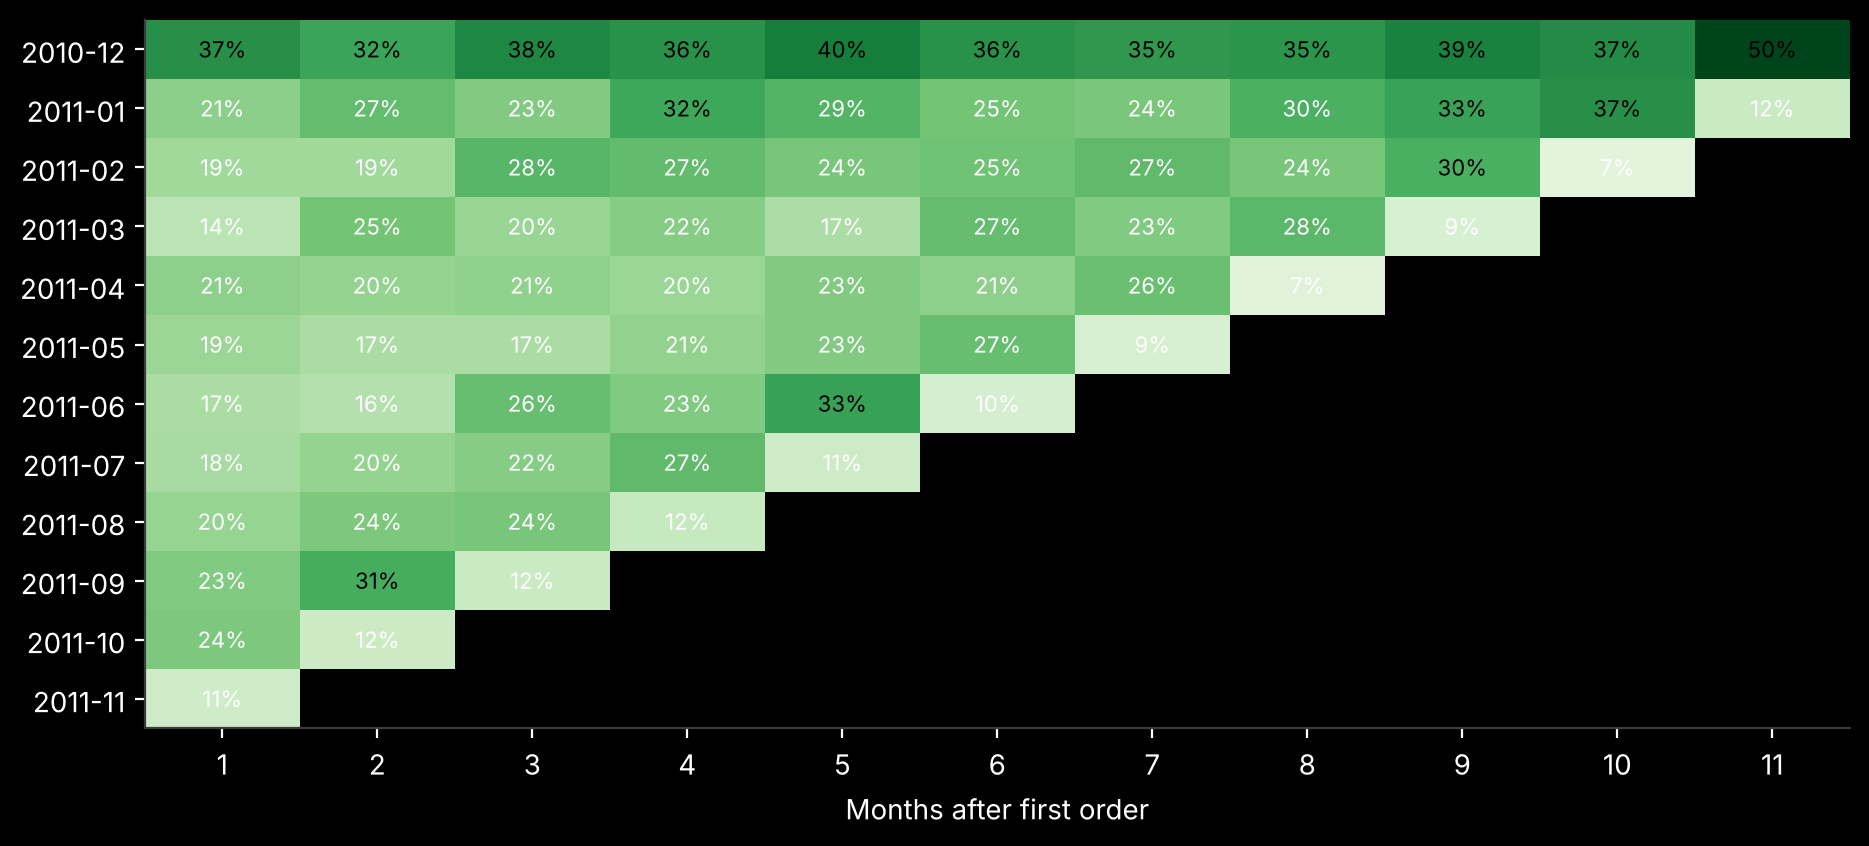

In [8]:
back = repeat_buying(sales).iloc[:-1, 1:12]
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.imshow(back.to_numpy(float), cmap="Greens", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(back.shape[1]), back.columns); ax.set_yticks(range(len(back)), [str(m) for m in back.index]); ax.grid(False)
ax.set_xlabel("Months after first order")
for (i, j), v in np.ndenumerate(back.to_numpy(float)):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v < 0.3 else "black", fontsize=8)
plt.show()

Customers who first bought in December 2010 kept returning at 30 to 50 percent a month. Later groups return at about half that rate. The earliest group likely includes long standing customers whose history starts before the data does.

## Named segments or clustering?

The first version of this project used k means clustering. So here is a fair contest. Both methods see only the sales before the last 90 days, and both make seven segments. Then the last 90 days show how well each one sorted customers.

The score is the share of the differences between customers that the segments account for. 0 is none and 1 is all.

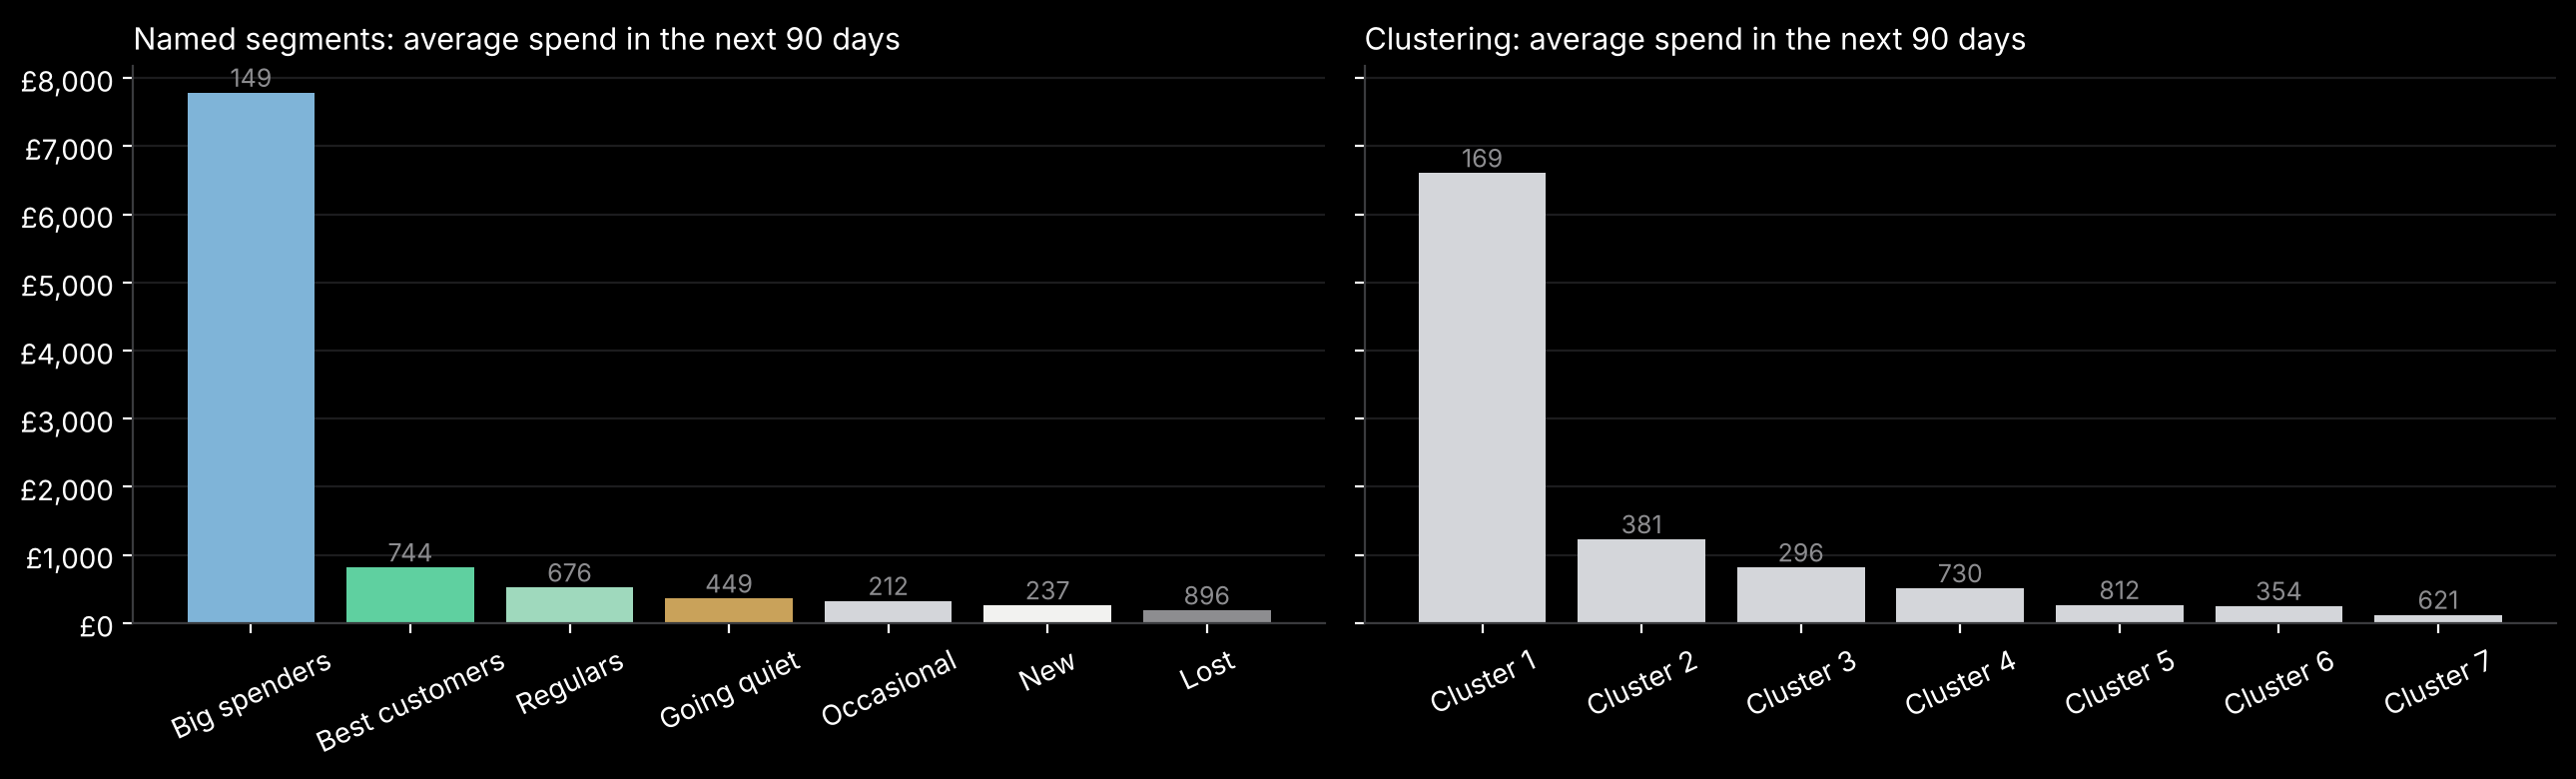

,"Named, without Big spenders","Named, with Big spenders",Clustering
Who came back,15%,15%,16%
What they spent,4%,15%,12%


In [9]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from retail_analysis.forward import split

before, after, cutoff = split(sales)
then = summarize(before, cutoff)
then["Named segments"] = group(then)
measures = StandardScaler().fit_transform(np.log1p(then[["days_since", "orders", "spend"]]))
then["Clustering"] = KMeans(7, n_init=10, random_state=0).fit_predict(measures)
spend_after = after.groupby("customer")["revenue"].sum()
then["came_back"] = then.index.isin(spend_after.index)
then["spend_after"] = spend_after.reindex(then.index).fillna(0)
then["Six segments"] = then["Named segments"].replace("Big spenders", "Best customers")       # the named segments before Big spenders was added

def explained(method, outcome):
    return 1 - then.groupby(method)[outcome].transform(lambda v: (v - v.mean()) ** 2).sum() / ((then[outcome] - then[outcome].mean()) ** 2).sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, method in zip(axes, ["Named segments", "Clustering"]):
    table = then.groupby(method).agg(spend=("spend_after", "mean"), customers=("spend_after", "size")).sort_values("spend", ascending=False)
    labels = table.index if method == "Named segments" else [f"Cluster {i + 1}" for i in range(len(table))]
    bars = ax.bar(labels, table.spend, color=[COLORS.get(i, SILVER) for i in table.index])
    ax.bar_label(bars, [f"{n:,}" for n in table.customers], color=GREY, fontsize=9)
    ax.set_title(f"{method}: average spend in the next 90 days", loc="left", fontsize=11); ax.tick_params(axis="x", rotation=25); ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()
pd.DataFrame({m: {"Who came back": explained(m, "came_back"), "What they spent": explained(m, "spend_after")} for m in ["Six segments", "Named segments", "Clustering"]}).rename(columns={"Six segments": "Named, without Big spenders", "Named segments": "Named, with Big spenders"}).style.format("{:.0%}")

The numbers over the bars are customers in each segment.

This contest is why Big spenders exists. With six named segments, clustering was far better on spend: 12 percent against 4. It had found a small cluster of very large buyers that the named segments were folding into Best customers, because they scored on recency and frequency and left spend out.

One rule fixed it. Splitting the top spenders out of Best customers takes the named segments from 4 percent to 15 on spend, ahead of clustering. Clustering is still slightly better at sorting who comes back, 16 percent against 15.

So the named segments stay. Each has a rule anyone can read, the same name means the same thing next month, and they now match or beat clustering where it counts.

## What this says

* **182 customers are 44 percent of the revenue.** Big spenders are the accounts this shop cannot lose.
* **About 650 customers are going quiet.** They have ordered several times and spent real money. That list is where a shop would start.
* **Each segment has a clear next step**, from knowing the Big spenders by name to winning a second order from new ones.
* **Clustering earned its place as a check.** It exposed a gap in the rules, and closing the gap put the rules ahead.